Tampilan Data Awal:
   patient_id gender  age  body_mass_index  smoker  systolic_blood_pressure  \
0  PT00030699      F   31             25.9       0                    112.0   
1  PT00018951      F   72             28.6       0                    125.0   
2  PT00027657      F   28              NaN       0                    102.0   
3  PT00099298      F   63              NaN       0                      NaN   
4  PT00050564      F   35              NaN       0                    111.0   

   hypertension_treated  family_history_of_cardiovascular_disease  \
0                     1                                         0   
1                     1                                         0   
2                     0                                         0   
3                     0                                         0   
4                     1                                         0   

   atrial_fibrillation  chronic_kidney_disease  rheumatoid_arthritis  \
0                 

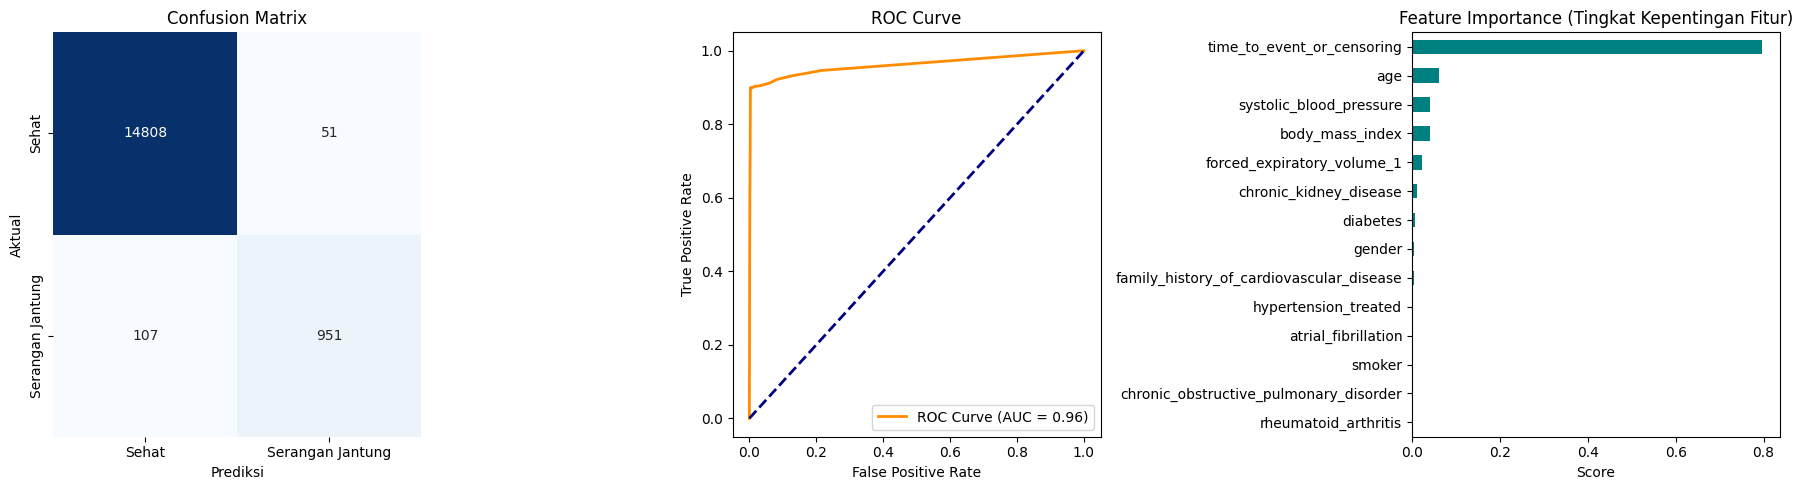


=== 5 Variabel Paling Berpengaruh ===
time_to_event_or_censoring    0.797585
age                           0.060509
systolic_blood_pressure       0.041319
body_mass_index               0.041243
forced_expiratory_volume_1    0.023413
dtype: float64


In [ ]:
# ==========================================
# 1. IMPORT LIBRARY
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

# ==========================================
# 2. LOAD DATASET
# ==========================================
file_path = 'Data3.csv'
df = pd.read_csv(file_path)

print("Tampilan Data Awal:")
print(df.head())
print("\nInfo Data Awal:")
print(df.info())

# ==========================================
# 3. PRA-PROSES DATA (DATA PREPROCESSING)
# ==========================================
if 'patient_id' in df.columns:
    df = df.drop(columns=['patient_id'])

numerical_cols_with_na = [
    'body_mass_index',
    'systolic_blood_pressure',
    'forced_expiratory_volume_1'
]

imputer = SimpleImputer(strategy='median')
df[numerical_cols_with_na] = imputer.fit_transform(df[numerical_cols_with_na])

le = LabelEncoder()
df['gender'] = le.fit_transform(df['gender'])

df['smoker'] = df['smoker'].astype(int)

print("\nCek Data setelah Preprocessing (Pastikan tidak ada null):")
print(df.isnull().sum())

# ==========================================
# 4. PEMBAGIAN DATA (TRAIN-TEST SPLIT)
# ==========================================
X = df.drop(columns=['heart_attack'])  #
y = df['heart_attack']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nJumlah Data Latih: {X_train.shape[0]}")
print(f"Jumlah Data Uji: {X_test.shape[0]}")

# ==========================================
# 5. PELATIHAN MODEL RANDOM FOREST
# ==========================================
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
print("\nModel berhasil dilatih!")

# ==========================================
# 6. EVALUASI MODEL
# ==========================================
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]  # Probabilitas untuk kelas positif

# Menghitung Metrik
acc = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_pred_proba)

print(f"\n=== HASIL EVALUASI ===")
print(f"Akurasi: {acc:.2%}")
print(f"AUC Score: {auc_score:.4f}")
print("\nLaporan Klasifikasi:")
print(class_report)

# ==========================================
# 7. VISUALISASI HASIL
# ==========================================
plt.figure(figsize=(18, 5))

# Plot 1: Confusion Matrix
plt.subplot(1, 3, 1)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.xticks([0.5, 1.5], ['Sehat', 'Serangan Jantung'])
plt.yticks([0.5, 1.5], ['Sehat', 'Serangan Jantung'])

# Plot 2: ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.subplot(1, 3, 2)
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.2f})', color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")

# Plot 3: Feature Importance
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
plt.subplot(1, 3, 3)
feature_importances.sort_values().plot(kind='barh', color='teal')
plt.title('Feature Importance (Tingkat Kepentingan Fitur)')
plt.xlabel('Score')

plt.tight_layout()
plt.show()

# Menampilkan Fitur Terpenting dalam bentuk teks
print("\n=== 5 Variabel Paling Berpengaruh ===")
print(feature_importances.sort_values(ascending=False).head(5))